In [1]:
import mne
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import warnings
from woody_filter import woody_stochastic

warnings.filterwarnings('ignore')

In [2]:
def analyze_subject(epochs_path, channel='FZ', theta_range=(4, 8), time_window=(0, 0.5)):
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    
    incorrect_codes = ['108', '109', '118', '119', '128', '129', '138', '139']
    epochs_incorrect = epochs[incorrect_codes]
    
    n_trials = len(epochs_incorrect)
    if n_trials < 5:
        return None
    
    data = epochs_incorrect.copy().pick([channel]).get_data()[:, 0, :]
    times = epochs_incorrect.times
    data_uv = data * 1e6
    sfreq = epochs_incorrect.info['sfreq']
    
    freqs = np.arange(4, 30, 0.5)
    n_cycles = freqs / 2.0
    baseline_mask = (times >= -0.5) & (times <= 0)
    
    # === RAW ===
    grand_avg_raw = data_uv.mean(axis=0)
    
    tfr_total_raw = np.zeros((len(freqs), len(times)))
    tfr_induced_raw = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        residual = data_uv[trial, :] - grand_avg_raw
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            conv_total = np.convolve(data_uv[trial, :], wavelet, mode='same')
            conv_induced = np.convolve(residual, wavelet, mode='same')
            tfr_total_raw[idx, :] += np.abs(conv_total) ** 2
            tfr_induced_raw[idx, :] += np.abs(conv_induced) ** 2
    tfr_total_raw /= n_trials
    tfr_induced_raw /= n_trials
    
    bl_total_raw = tfr_total_raw[:, baseline_mask].mean(axis=1, keepdims=True)
    bl_induced_raw = tfr_induced_raw[:, baseline_mask].mean(axis=1, keepdims=True)
    tfr_total_raw_pct = ((tfr_total_raw - bl_total_raw) / bl_total_raw) * 100
    tfr_induced_raw_pct = ((tfr_induced_raw - bl_induced_raw) / bl_induced_raw) * 100
    
    # === STOCHASTIC WOODY ===
    aligned_avg, detected_lags, _ = woody_stochastic(
        data_uv.T, tol=0.1, max_it=100, n_runs=1000, max_lag_init=10, xcorr_mthd='unbiased', max_shift=50
    )
    
    aligned_trials = np.zeros_like(data_uv)
    for i in range(n_trials):
        lag = detected_lags[i]
        if lag > 0:
            aligned_trials[i, :] = np.concatenate([data_uv[i, lag:], np.zeros(lag)])
        elif lag < 0:
            aligned_trials[i, :] = np.concatenate([np.zeros(-lag), data_uv[i, :lag]])
        else:
            aligned_trials[i, :] = data_uv[i, :]
    
    grand_avg_woody = aligned_trials.mean(axis=0)
    
    tfr_total_woody = np.zeros((len(freqs), len(times)))
    tfr_induced_woody = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        residual = aligned_trials[trial, :] - grand_avg_woody
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            conv_total = np.convolve(aligned_trials[trial, :], wavelet, mode='same')
            conv_induced = np.convolve(residual, wavelet, mode='same')
            tfr_total_woody[idx, :] += np.abs(conv_total) ** 2
            tfr_induced_woody[idx, :] += np.abs(conv_induced) ** 2
    tfr_total_woody /= n_trials
    tfr_induced_woody /= n_trials
    
    bl_total_woody = tfr_total_woody[:, baseline_mask].mean(axis=1, keepdims=True)
    bl_induced_woody = tfr_induced_woody[:, baseline_mask].mean(axis=1, keepdims=True)
    tfr_total_woody_pct = ((tfr_total_woody - bl_total_woody) / bl_total_woody) * 100
    tfr_induced_woody_pct = ((tfr_induced_woody - bl_induced_woody) / bl_induced_woody) * 100
    
    # === WOODY + REGRESSION ===
    trials_woody_reg = np.zeros_like(aligned_trials)
    for t_idx in range(n_trials):
        slope, intercept, _, _, _ = linregress(grand_avg_woody, aligned_trials[t_idx, :])
        trials_woody_reg[t_idx, :] = aligned_trials[t_idx, :] - (intercept + slope * grand_avg_woody)
    
    grand_avg_woody_reg = trials_woody_reg.mean(axis=0)
    
    tfr_induced_woody_reg = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(trials_woody_reg[trial, :], wavelet, mode='same')
            tfr_induced_woody_reg[idx, :] += np.abs(convolved) ** 2
    tfr_induced_woody_reg /= n_trials
    
    bl_induced_woody_reg = tfr_induced_woody_reg[:, baseline_mask].mean(axis=1, keepdims=True)
    tfr_induced_woody_reg_pct = ((tfr_induced_woody_reg - bl_induced_woody_reg) / bl_induced_woody_reg) * 100
    
    # === EXTRACT THETA ===
    theta_mask = (freqs >= theta_range[0]) & (freqs <= theta_range[1])
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    
    return {
        'n_trials': n_trials,
        'mean_lag': detected_lags.mean(),
        'std_lag': detected_lags.std(),
        'theta_total_raw': tfr_total_raw_pct[theta_mask, :][:, time_mask].mean(),
        'theta_induced_raw': tfr_induced_raw_pct[theta_mask, :][:, time_mask].mean(),
        'theta_total_woody': tfr_total_woody_pct[theta_mask, :][:, time_mask].mean(),
        'theta_induced_woody': tfr_induced_woody_pct[theta_mask, :][:, time_mask].mean(),
        'theta_induced_woody_reg': tfr_induced_woody_reg_pct[theta_mask, :][:, time_mask].mean(),
        'erp_raw': grand_avg_raw,
        'erp_woody': grand_avg_woody,
        'erp_woody_reg': grand_avg_woody_reg,
        'tfr_induced_raw_pct': tfr_induced_raw_pct,
        'tfr_induced_woody_pct': tfr_induced_woody_pct,
        'tfr_induced_woody_reg_pct': tfr_induced_woody_reg_pct,
        'times': times,
        'freqs': freqs
    }

In [3]:
subjects = [
    'sub-AG05AS29', 'sub-AH17AR05', 'sub-AL07NK06', 'sub-AL08AS02', 'sub-AR06AS06',
    'sub-AR10IO04', 'sub-AT06ED25', 'sub-AU09GE22', 'sub-CH04ER19', 'sub-CH05NK28',
    'sub-CH06UT07', 'sub-CH07AD15', 'sub-CH09AS13', 'sub-CK04NS18', 'sub-CK06ED08',
    'sub-CK06ST11', 'sub-CK06US15', 'sub-DADARE11', 'sub-DT05EV26', 'sub-DT07ES22',
    'sub-DTINTZ10', 'sub-EK05AN14', 'sub-EK06ER26', 'sub-EK07CH24', 'sub-EL05JO26',
    'sub-EL06LD17', 'sub-EL07EL14', 'sub-EN04ER01', 'sub-EN05AN02', 'sub-EN05KT02',
    'sub-EN05US05', 'sub-EN06AN21', 'sub-EN08CH27', 'sub-EP05EN09', 'sub-ER03ER09',
    'sub-ER04ER12', 'sub-ER04RT24', 'sub-ER05AN13', 'sub-ER05AV01', 'sub-ER05EL09',
    'sub-ER05EL26', 'sub-ER05ER07', 'sub-ER05IM29', 'sub-ER05MA17', 'sub-ER05NG11',
    'sub-ER05RK06', 'sub-ER05RT24', 'sub-ER06EL06', 'sub-ER06EN27', 'sub-ER06ET15',
    'sub-ER06IS22', 'sub-ER06US24', 'sub-ER07AN28', 'sub-ER07AS24', 'sub-ER07EF15',
    'sub-ER07EL10', 'sub-ER07ER23', 'sub-ER07ER30', 'sub-ER07RL02', 'sub-ER08AS28',
    'sub-ER08EN05', 'sub-ER09NK30', 'sub-ES06ER27', 'sub-ES06NK11', 'sub-EZ04SE15',
    'sub-GA04LI18', 'sub-HEERLD19', 'sub-IA05NS20', 'sub-ID07EN28', 'sub-IG06AI28',
    'sub-IG06LF01', 'sub-IG06NS07', 'sub-IG06WE03', 'sub-IG07RT16', 'sub-IK06ET06',
    'sub-IK09LD05', 'sub-IN05ED23', 'sub-IN06AS14', 'sub-IS06RG09', 'sub-IT08ND26',
    'sub-JU05IN24', 'sub-KA04LF11', 'sub-KE05AN23', 'sub-KE07AN05', 'sub-KE07ER04',
    'sub-KE08AS23', 'sub-KN05EN09', 'sub-KO07EL16', 'sub-LA08RE26', 'sub-LO06RE10',
    'sub-LY07EL23', 'sub-MA06LO21', 'sub-ME05NS04', 'sub-NA04AV25', 'sub-ND05NG06',
    'sub-ND06EF01', 'sub-NE06AS01', 'sub-NE06EL01', 'sub-NG03YI17', 'sub-NG06EA08',
    'sub-NK06AS24', 'sub-NK06RG30', 'sub-NN04AN24', 'sub-NN05AN05', 'sub-NN05IR17',
    'sub-NN06TH16', 'sub-NN07EN14', 'sub-NN07ID18', 'sub-NN08AS03', 'sub-NN08EL29',
    'sub-NN08ER22', 'sub-NN08LM06', 'sub-NN09LM18', 'sub-NN09NS31', 'sub-NO05RT22',
    'sub-NS09EL05', 'sub-NY04DT26', 'sub-NZ04EN16', 'sub-NZ09ER04', 'sub-OH05NK29',
    'sub-ON05EL22', 'sub-OW07RK26', 'sub-PP07AS29', 'sub-RASUAN07', 'sub-RF09EL18',
    'sub-RG05RS16', 'sub-RG06AS09', 'sub-RO06AN18', 'sub-RT07LD06', 'sub-RYRAAN26',
    'sub-RZ05ND19', 'sub-SA05AH22', 'sub-SE05AS26', 'sub-SE05ZI24', 'sub-SE06AM29',
    'sub-SE06NS17', 'sub-ST03ED03', 'sub-ST07NK15', 'sub-TA03RL11', 'sub-TE05AS09',
    'sub-TE05NS01', 'sub-TE10AN12', 'sub-TH07AR12', 'sub-TH08ER21', 'sub-TT06LF28',
    'sub-TT08NS17', 'sub-TZ08US31', 'sub-US07US10', 'sub-US08KE27', 'sub-VA05AS27',
    'sub-VA05OR26', 'sub-VA06NZ29', 'sub-VA06OV12', 'sub-WA04EJ22', 'sub-WA05EJ08',
    'sub-XX04AS28'
]

data_dir = Path('/Users/qmoreau/Documents/Work/flanker_bursts/PreprocessedData/ernpipeline/')

all_results = []
for sub_id in tqdm(subjects):
    sub_file = data_dir / sub_id / f'{sub_id}_desc-epochs_eeg.fif'
    if not sub_file.exists():
        continue
    try:
        results = analyze_subject(sub_file)
        if results is not None:
            results['subject'] = sub_id
            all_results.append(results)
    except:
        continue

print(f'{len(all_results)} subjects')

  0%|          | 0/156 [00:00<?, ?it/s]

Run 0/1000: New best corr = 0.4356


  1%|          | 1/156 [00:02<05:34,  2.16s/it]


Best correlation: 0.4545
Lag range: [-8, 46] samples
Lag std: 16.44 samples
Run 0/1000: New best corr = 0.5516

Best correlation: 0.5532
Lag range: [-49, 60] samples
Lag std: 25.24 samples


  1%|▏         | 2/156 [00:14<21:23,  8.34s/it]

Run 0/1000: New best corr = 0.4360


... (302 outputs left out)

 99%|█████████▉| 155/156 [18:50<00:08,  8.42s/it]

Run 0/1000: New best corr = 0.2667

Best correlation: 0.2834
Lag range: [-59, 59] samples
Lag std: 28.36 samples


100%|██████████| 156/156 [19:04<00:00,  7.34s/it]

155 subjects


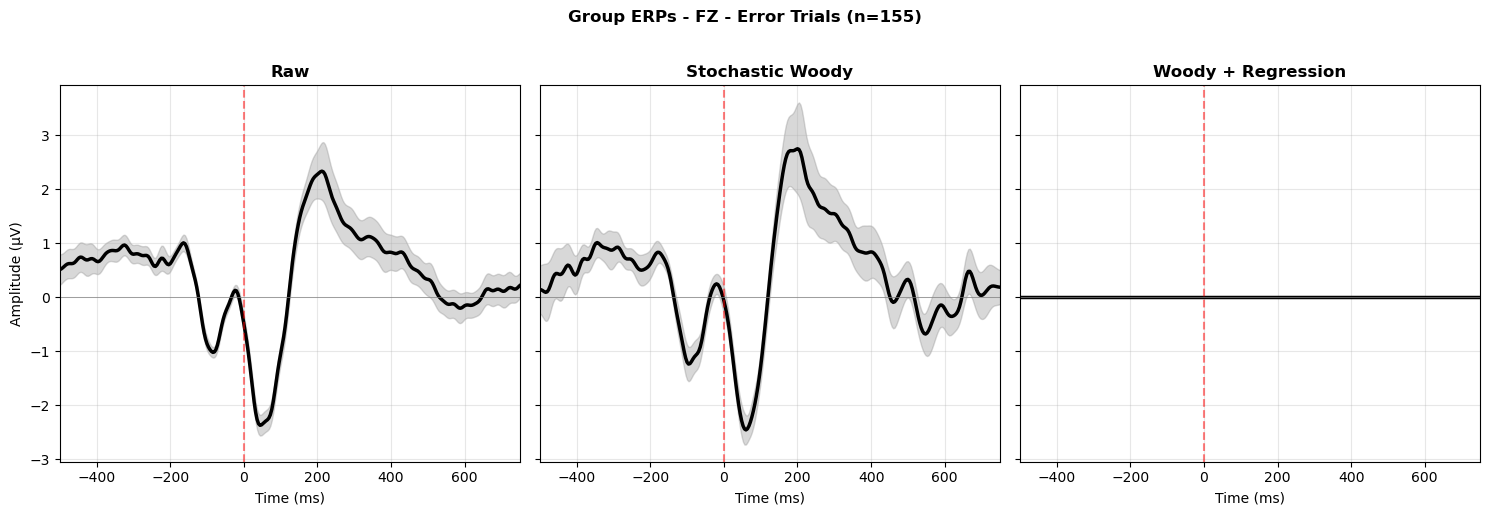

In [4]:
times = all_results[0]['times']
freqs = all_results[0]['freqs']

erp_raw_all = np.array([r['erp_raw'] for r in all_results])
erp_woody_all = np.array([r['erp_woody'] for r in all_results])
erp_woody_reg_all = np.array([r['erp_woody_reg'] for r in all_results])

erp_raw_mean = erp_raw_all.mean(axis=0)
erp_raw_sem = erp_raw_all.std(axis=0) / np.sqrt(len(all_results))
erp_woody_mean = erp_woody_all.mean(axis=0)
erp_woody_sem = erp_woody_all.std(axis=0) / np.sqrt(len(all_results))
erp_woody_reg_mean = erp_woody_reg_all.mean(axis=0)
erp_woody_reg_sem = erp_woody_reg_all.std(axis=0) / np.sqrt(len(all_results))

tfr_induced_raw_mean = np.array([r['tfr_induced_raw_pct'] for r in all_results]).mean(axis=0)
tfr_induced_woody_mean = np.array([r['tfr_induced_woody_pct'] for r in all_results]).mean(axis=0)
tfr_induced_woody_reg_mean = np.array([r['tfr_induced_woody_reg_pct'] for r in all_results]).mean(axis=0)

# ERPs
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, erp_mean, erp_sem, title in zip(axes, 
    [erp_raw_mean, erp_woody_mean, erp_woody_reg_mean],
    [erp_raw_sem, erp_woody_sem, erp_woody_reg_sem],
    ['Raw', 'Stochastic Woody', 'Woody + Regression']):
    ax.plot(times * 1000, erp_mean, 'k', linewidth=2.5)
    ax.fill_between(times * 1000, erp_mean - erp_sem, erp_mean + erp_sem, color='gray', alpha=0.3)
    ax.axvline(0, color='r', linestyle='--', alpha=0.5)
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.set_xlim(-500, 750); ax.set_xlabel('Time (ms)')
    ax.set_title(title, fontweight='bold')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Amplitude (µV)')
plt.suptitle(f'Group ERPs - FZ - Error Trials (n={len(all_results)})', fontweight='bold', y=1.02)
plt.tight_layout()

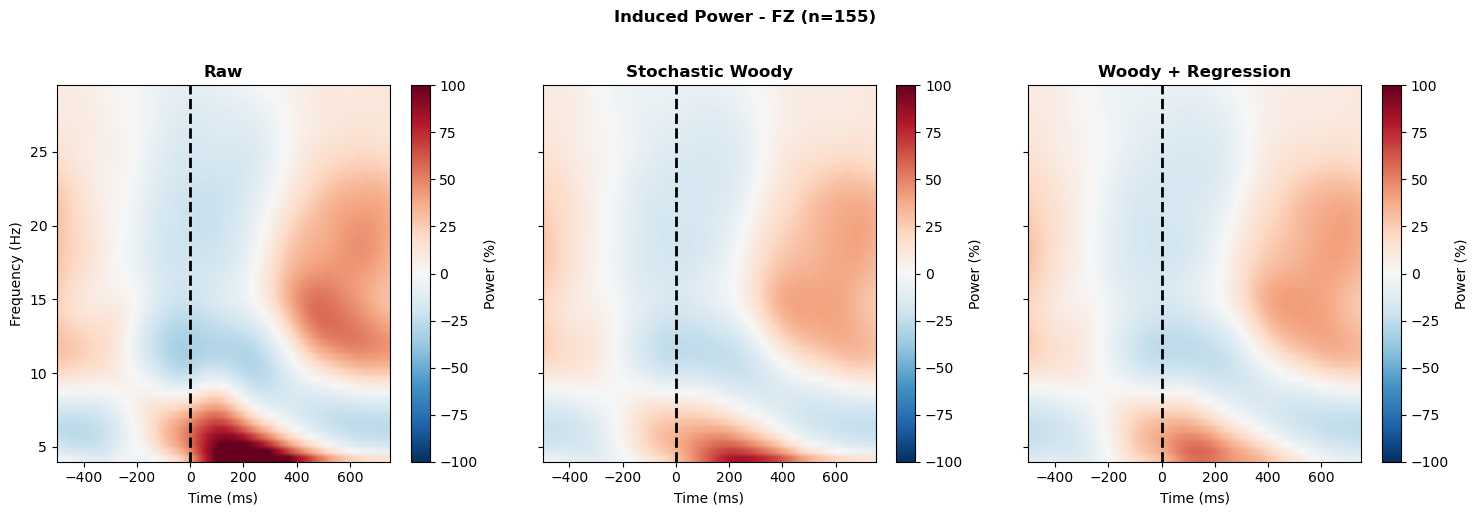

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, tfr_mean, title in zip(axes,
    [tfr_induced_raw_mean, tfr_induced_woody_mean, tfr_induced_woody_reg_mean],
    ['Raw', 'Stochastic Woody', 'Woody + Regression']):
    im = ax.imshow(tfr_mean, aspect='auto', origin='lower',
                   extent=[times[0]*1000, times[-1]*1000, freqs[0], freqs[-1]],
                   vmin=-100, vmax=100, cmap='RdBu_r')
    ax.axvline(0, color='black', linestyle='--', linewidth=2)
    ax.set_xlim(-500, 750); ax.set_xlabel('Time (ms)')
    ax.set_title(title, fontweight='bold')
    plt.colorbar(im, ax=ax, label='Power (%)')
axes[0].set_ylabel('Frequency (Hz)')
plt.suptitle(f'Induced Power - FZ (n={len(all_results)})', fontweight='bold', y=1.02)
plt.tight_layout()

Raw    - Total: 52.8±6.6%, Induced: 43.0±5.6%
Woody  - Total: 48.1±6.8%, Induced: 23.3±3.1%
W+Reg  - Induced: 17.9±2.2%


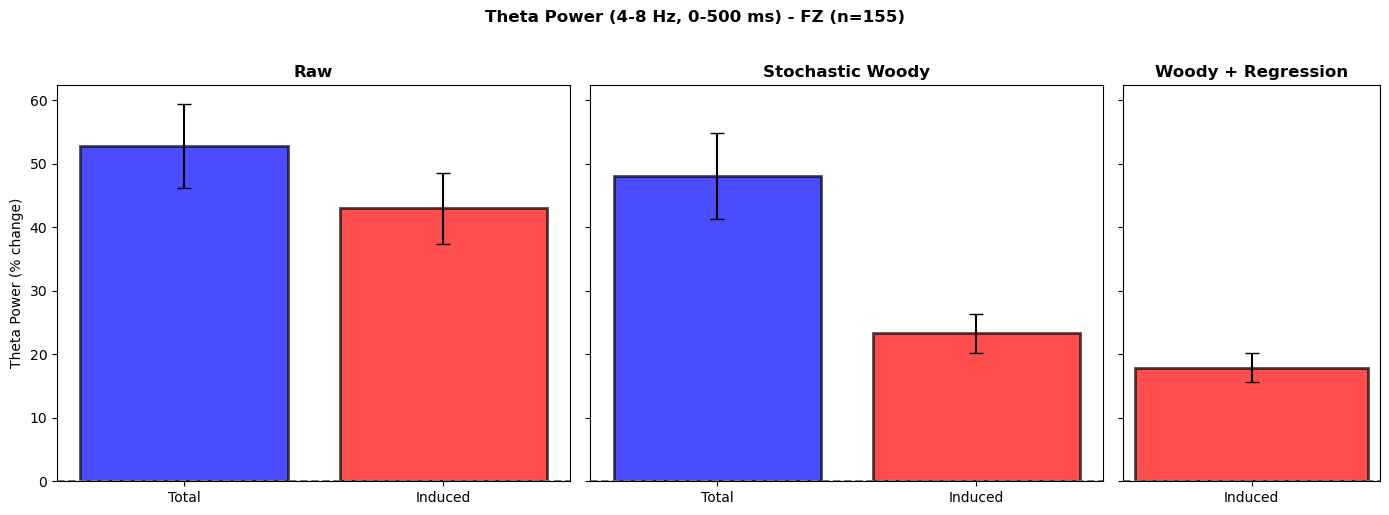

In [6]:
df = pd.DataFrame([{k: v for k, v in r.items() if not isinstance(v, np.ndarray)} for r in all_results])

fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True, gridspec_kw={'width_ratios': [2, 2, 1]})

x_pos = np.arange(2)

# Raw
raw_means = [df['theta_total_raw'].mean(), df['theta_induced_raw'].mean()]
raw_sems = [df['theta_total_raw'].sem(), df['theta_induced_raw'].sem()]
axes[0].bar(x_pos, raw_means, yerr=raw_sems, color=['blue', 'red'], alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[0].set_xticks(x_pos); axes[0].set_xticklabels(['Total', 'Induced'])
axes[0].axhline(0, color='gray', linestyle='--')
axes[0].set_ylabel('Theta Power (% change)'); axes[0].set_title('Raw', fontweight='bold')

# Woody
woody_means = [df['theta_total_woody'].mean(), df['theta_induced_woody'].mean()]
woody_sems = [df['theta_total_woody'].sem(), df['theta_induced_woody'].sem()]
axes[1].bar(x_pos, woody_means, yerr=woody_sems, color=['blue', 'red'], alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[1].set_xticks(x_pos); axes[1].set_xticklabels(['Total', 'Induced'])
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set_title('Stochastic Woody', fontweight='bold')

# Woody + Regression
woody_reg_mean = df['theta_induced_woody_reg'].mean()
woody_reg_sem = df['theta_induced_woody_reg'].sem()
axes[2].bar([0], [woody_reg_mean], yerr=[woody_reg_sem], color='red', alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[2].set_xticks([0]); axes[2].set_xticklabels(['Induced'])
axes[2].axhline(0, color='gray', linestyle='--')
axes[2].set_title('Woody + Regression', fontweight='bold')

plt.suptitle(f'Theta Power (4-8 Hz, 0-500 ms) - FZ (n={len(df)})', fontweight='bold', y=1.02)
plt.tight_layout()

print(f'Raw    - Total: {raw_means[0]:.1f}±{raw_sems[0]:.1f}%, Induced: {raw_means[1]:.1f}±{raw_sems[1]:.1f}%')
print(f'Woody  - Total: {woody_means[0]:.1f}±{woody_sems[0]:.1f}%, Induced: {woody_means[1]:.1f}±{woody_sems[1]:.1f}%')
print(f'W+Reg  - Induced: {woody_reg_mean:.1f}±{woody_reg_sem:.1f}%')

In [7]:
import sys
sys.path.append('/Users/qmoreau/Documents/ERN_sim/lagged_hilbert_autocoherence/python')
from lagged_autocoherence import lagged_hilbert_autocoherence

In [8]:
def analyze_autocoherence(epochs_path, freqs_range, lags_range, time_window=(-1, 1.5)):
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    
    incorrect_codes = ['108', '109', '118', '119', '128', '129', '138', '139']
    epochs_incorrect = epochs[incorrect_codes]
    
    n_trials = len(epochs_incorrect)
    if n_trials < 10:
        return None
    
    data = epochs_incorrect.copy().pick(['FZ']).get_data()[:, 0, :]
    times = epochs_incorrect.times
    data_uv = data * 1e6
    sfreq = epochs_incorrect.info['sfreq']
    
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    data_cropped = data_uv[:, time_mask]
    
    # Raw induced
    grand_avg_raw = data_cropped.mean(axis=0)
    data_induced_raw = data_cropped - grand_avg_raw
    
    # Woody alignment
    aligned_avg, detected_lags, _ = woody_stochastic(
        data_uv.T, tol=0.1, max_it=100, n_runs=1000, max_lag_init=10, xcorr_mthd='unbiased', max_shift=50
    )
    
    aligned_trials = np.zeros_like(data_uv)
    for i in range(n_trials):
        lag = detected_lags[i]
        if lag > 0:
            aligned_trials[i, :] = np.concatenate([data_uv[i, lag:], np.zeros(lag)])
        elif lag < 0:
            aligned_trials[i, :] = np.concatenate([np.zeros(-lag), data_uv[i, :lag]])
        else:
            aligned_trials[i, :] = data_uv[i, :]
    
    data_woody_cropped = aligned_trials[:, time_mask]
    grand_avg_woody = data_woody_cropped.mean(axis=0)
    data_induced_woody = data_woody_cropped - grand_avg_woody
    
    # Woody + regression
    data_induced_woody_reg = np.zeros_like(data_woody_cropped)
    for t_idx in range(n_trials):
        slope, intercept, _, _, _ = linregress(grand_avg_woody, data_woody_cropped[t_idx, :])
        data_induced_woody_reg[t_idx, :] = data_woody_cropped[t_idx, :] - (intercept + slope * grand_avg_woody)
    
    # Compute autocoherence
    lhc_raw = lagged_hilbert_autocoherence(data_induced_raw, freqs_range, lags_range, srate=sfreq, df=1.0)
    lhc_woody = lagged_hilbert_autocoherence(data_induced_woody, freqs_range, lags_range, srate=sfreq, df=1.0)
    lhc_woody_reg = lagged_hilbert_autocoherence(data_induced_woody_reg, freqs_range, lags_range, srate=sfreq, df=1.0)
    
    return {
        'subject': Path(epochs_path).parent.name,
        'n_trials': n_trials,
        'lhc_raw': lhc_raw,
        'lhc_woody': lhc_woody,
        'lhc_woody_reg': lhc_woody_reg
    }

In [9]:
freqs_range = np.arange(4, 30, 1)
lags_range = np.arange(0.5, 5, 0.25)

all_lhc = []
for sub_id in tqdm(subjects):
    sub_file = data_dir / sub_id / f'{sub_id}_desc-epochs_eeg.fif'
    if not sub_file.exists():
        continue
    try:
        results = analyze_autocoherence(sub_file, freqs_range, lags_range)
        if results is not None:
            all_lhc.append(results)
    except Exception as e:
        continue

print(f'{len(all_lhc)} subjects')

  0%|          | 0/156 [00:00<?, ?it/s]

Run 0/1000: New best corr = 0.4364

Best correlation: 0.4535
Lag range: [-9, 46] samples
Lag std: 16.62 samples


  1%|          | 1/156 [00:04<11:53,  4.60s/it]

Run 0/1000: New best corr = 0.5491

Best correlation: 0.5533
Lag range: [-52, 60] samples
Lag std: 25.32 samples


  1%|▏         | 2/156 [00:25<36:51, 14.36s/it]

Run 0/1000: New best corr = 0.4316

Best correlation: 0.4653
Lag range: [-17, 13] samples
Lag std: 8.31 samples


... (302 outputs left out)

 99%|█████████▉| 155/156 [29:37<00:13, 13.17s/it]

Run 0/1000: New best corr = 0.2725

Best correlation: 0.2826
Lag range: [-50, 60] samples
Lag std: 25.57 samples


100%|██████████| 156/156 [29:59<00:00, 11.54s/it]

155 subjects


Theta LHaC - Raw: 0.130, Woody: 0.129, W+Reg: 0.128


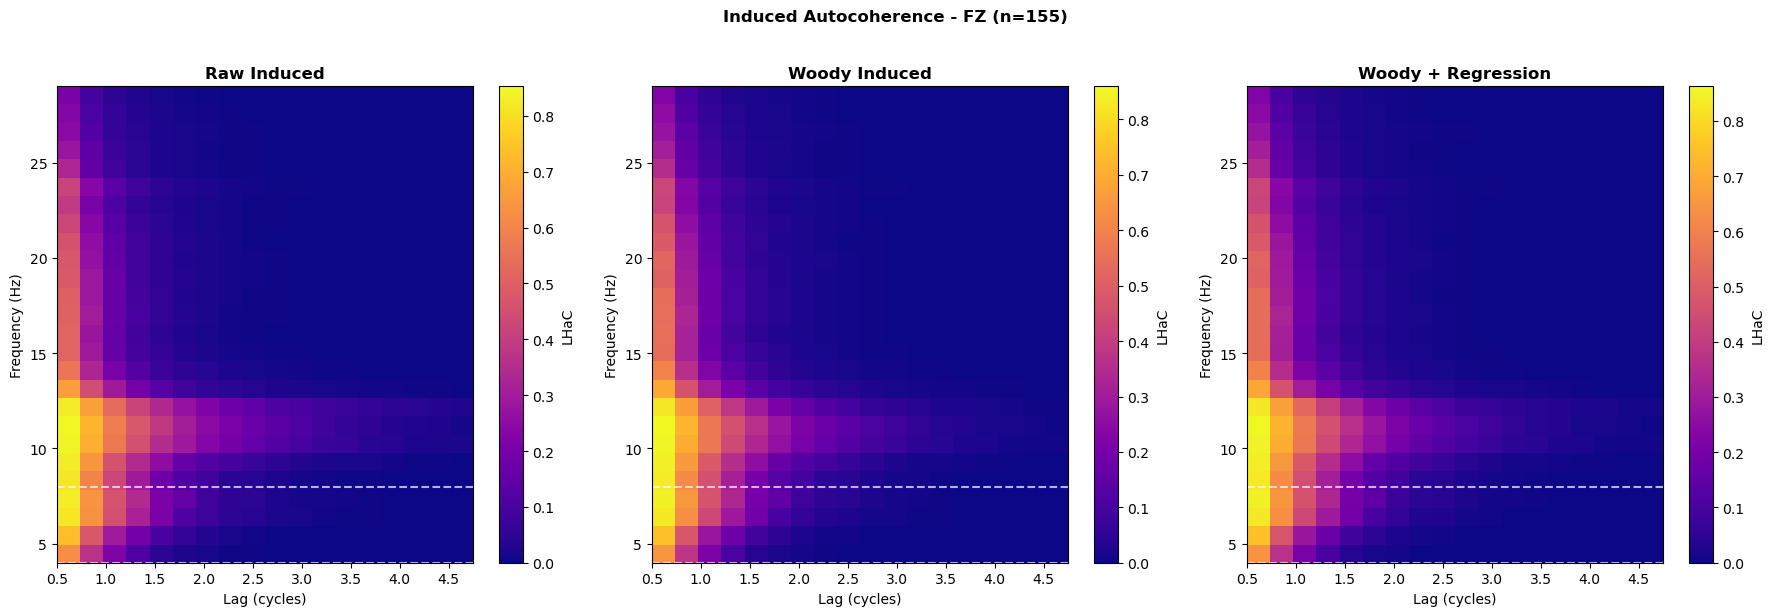

In [10]:
lhc_raw_all = np.array([r['lhc_raw'].mean(axis=0) for r in all_lhc])
lhc_woody_all = np.array([r['lhc_woody'].mean(axis=0) for r in all_lhc])
lhc_woody_reg_all = np.array([r['lhc_woody_reg'].mean(axis=0) for r in all_lhc])

lhc_raw_mean = lhc_raw_all.mean(axis=0)
lhc_woody_mean = lhc_woody_all.mean(axis=0)
lhc_woody_reg_mean = lhc_woody_reg_all.mean(axis=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, lhc_mean, title in zip(axes,
    [lhc_raw_mean, lhc_woody_mean, lhc_woody_reg_mean],
    ['Raw Induced', 'Woody Induced', 'Woody + Regression']):
    im = ax.imshow(lhc_mean, aspect='auto', origin='lower', cmap='plasma',
                   extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
    ax.axhline(4, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
    ax.axhline(8, color='white', linestyle='--', linewidth=1.5, alpha=0.7)
    ax.set_xlabel('Lag (cycles)'); ax.set_ylabel('Frequency (Hz)')
    ax.set_title(title, fontweight='bold')
    plt.colorbar(im, ax=ax, label='LHaC')

plt.suptitle(f'Induced Autocoherence - FZ (n={len(all_lhc)})', fontweight='bold', y=1.02)
plt.tight_layout()

# Theta stats
theta_mask = (freqs_range >= 4) & (freqs_range <= 8)
theta_raw = lhc_raw_mean[theta_mask, :].mean()
theta_woody = lhc_woody_mean[theta_mask, :].mean()
theta_woody_reg = lhc_woody_reg_mean[theta_mask, :].mean()

print(f'Theta LHaC - Raw: {theta_raw:.3f}, Woody: {theta_woody:.3f}, W+Reg: {theta_woody_reg:.3f}')